1. Los datos de Fashion MNIST están disponibles directamente en la API de conjuntos de datos de tf.keras. Los puedes cargar así:
mnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels), (test_images, test_labels) = mnist.load_data()

In [1]:
import tensorflow as tf
from keras.src.models import model

mnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels), (test_images, test_labels) = mnist.load_data()

I0000 00:00:1795447040.268474    7533 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795447040.932228    7533 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795447042.113530    7533 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [9]:
training_images.shape, training_labels.shape

((60000, 28, 28), (60000,))

In [10]:
test_images.shape, test_labels.shape

((10000, 28, 28), (10000,))

2. Visualiza el contenido de training_images[0] con un print. ¿Cuál es su forma? ¿Qué tipo de dato contiene?
Puedes visualizar una imagen en matplotlib.pyplot con el método imshow, que recibe como parámetro la imagen que quieres mostrar.

In [29]:
print(training_images[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 23

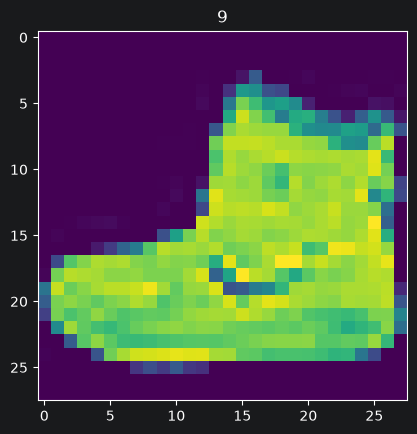

In [7]:
import matplotlib.pyplot as plt
plt.title(training_labels[0])
plt.imshow(training_images[0])

3. ¿Cuántas clases diferentes de ropa hay? Visualiza en una figura de matplotlib, 10 elementos de cada clase.

4. De las etiquetas verdaderas, crea la siguiente lista de clases:
class_names = ['Camiseta', 'Pantalón', 'Jersey', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Bota']
x,idx = tf.unique(training_labels)
for i in x:
    print(class_names[i])

In [8]:
tf.unique(training_labels)

W0000 00:00:1795447251.671205    8042 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1795447251.965983    7533 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Unique(y=<tf.Tensor: shape=(10,), dtype=uint8, numpy=array([9, 0, 3, 2, 7, 5, 1, 6, 4, 8], dtype=uint8)>, idx=<tf.Tensor: shape=(60000,), dtype=int32, numpy=array([0, 1, 1, ..., 2, 1, 5], shape=(60000,), dtype=int32)>)

Camiseta
Pantalón
Jersey
Vestido
Abrigo
Sandalia
Camisa
Zapatilla
Bolso
Bota


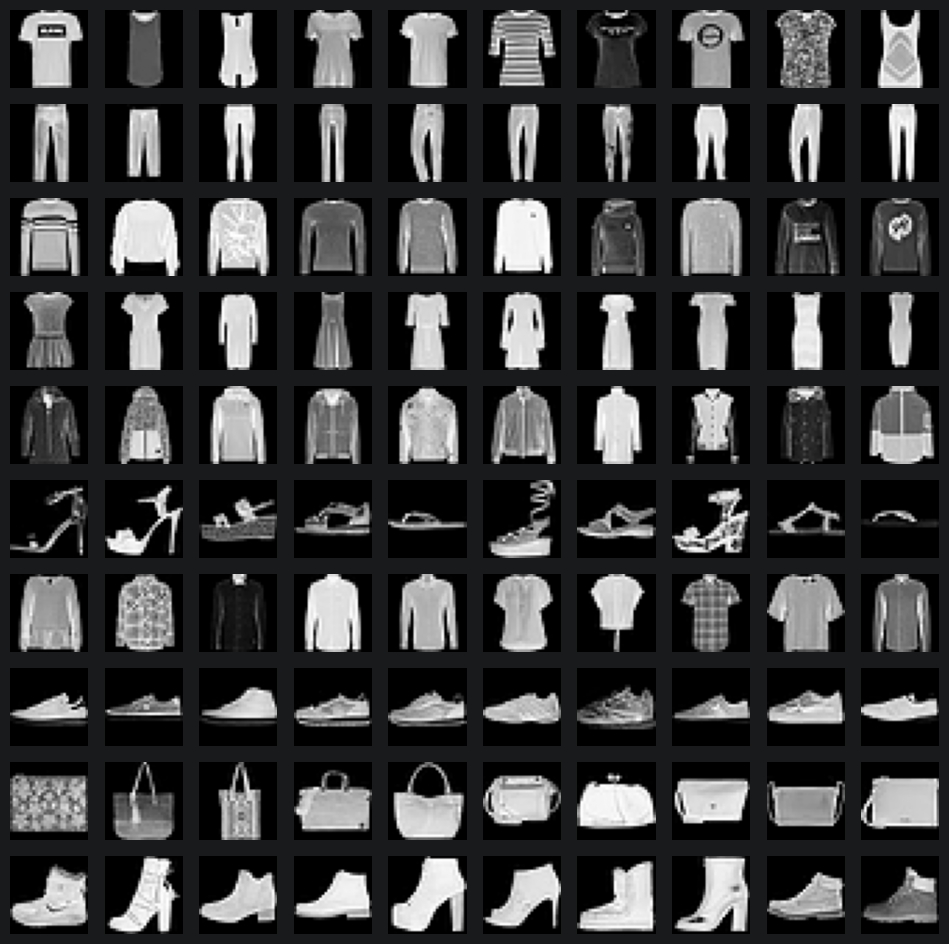

In [39]:
class_names = ['Camiseta', 'Pantalón', 'Jersey', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Bota']
x,idx = tf.unique(training_labels)
fig, axes = plt.subplots(10, 10, figsize=(12, 12))
for i in range(10):
    print(class_names[i])
    for j in range(10):
        # Encontrar la primera imagen de la clase i
        idx = (training_labels == i).nonzero()[0][j]
        axes[i, j].imshow(training_images[idx], cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(class_names[i])

5. Cuando trabajamos con imágenes, para pasarlas a una RNA, es mejor escalar los valores de sus píxeles. Normalizar es simplemente convertir los valores de los píxeles a un rango 0-1 en lugar de un rango 0-255 (valores posibles de un byte). Por tanto, tan sólo tienes que dividir todos los pixeles entre 255. Puedes investigar sobre lo que es el MinMaxScaler. Escala los valores de los píxeles de todas las imágenes.

In [40]:
training_images = training_images / 255.0
test_images = test_images / 255.0

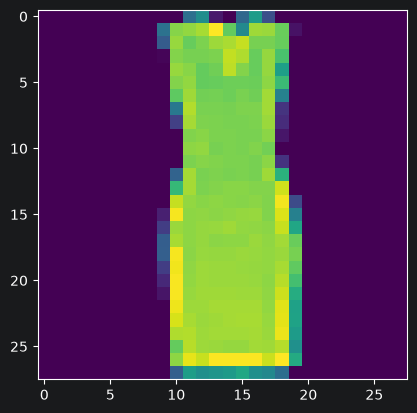

In [42]:
import random as rnd
plt.imshow(training_images[rnd.choice(range(0,len(training_images)))])

6. Crea un modelo de keras para que aprenda las diferencias entre las clases de ropa. ¿Qué forma tendrá la capa de entrada? Para que la RNA procese mejor la primera capa, hay que aplicar una capa llamada Flatten, que “aplana la matriz que representa todos los píxeles de la imagen. Por tanto, la primera capa de tu modelo será:
#define la primera capa, junto con la forma de la entrada tf.keras.layers.Flatten(input_shape=(28,28))

Introduce también en el modelo una capa oculta de 128 neuronas con la función de activación ‘relu’.
¿Cómo debe ser la capa de salida? ¿Qué función de activación debe tener?

In [44]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

7. Compila el modelo utilizando el método compile con el optimizador Adam, función de pérdida sparse_categorical_crossentropy y utilizando como métrica “Accuracy”.

In [46]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

8. Entrena el conjunto training_images durante 5 épocas. ¿Qué resultados obtienes? ¿Te parecen buenos?

In [47]:
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 751us/step - accuracy: 0.8248 - loss: 0.5009
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 701us/step - accuracy: 0.8643 - loss: 0.3792
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 699us/step - accuracy: 0.8782 - loss: 0.3403
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 698us/step - accuracy: 0.8827 - loss: 0.3175
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 699us/step - accuracy: 0.8919 - loss: 0.2944


9. Evalúa el modelo con el conjunto de test y comenta los resultados que has obtenidos

In [49]:
model.evaluate(test_images, test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 511us/step - accuracy: 0.8797 - loss: 0.3431


[0.3430969715118408, 0.8797000050544739]

10. Ejecuta el siguiente código:
classifications = model.predict(test_images)
print(classifications[0])

La salida, después de ejecutarla, es una lista de números. ¿Por qué crees que es así y qué representan esos números? ¿Qué representa esta lista? Elige la respuesta de entre las siguientes opciones
    a) Los 10 valores aleatorios menos significativos
    b) Las 10 primeras clasificaciones que hizo la RNA
    c) La probabilidad de que el elemento sea de cada una de las 10 clases

In [50]:
classifications = model.predict(test_images)
print(classifications[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 397us/step
[4.9611567e-06 4.3116266e-08 6.4927940e-07 3.8776045e-07 9.7621762e-07
 5.1205818e-02 6.3323100e-06 2.8028829e-02 4.8495331e-04 9.2026705e-01]


In [52]:
tf.argmax(classifications[0])

<tf.Tensor: shape=(), dtype=int64, numpy=9>

12. Prueba a cargar una imagen que hayas diseñado tú, escribe el código necesario para cargar la imagen y predecir su clase. Puedes utilizar la función imread del paquete cv2 (Computer Vision 2):
import cv2
mi_imagen=cv2.imread('miImagen.png',cv2.IMREAD_GRAYSCALE)
plt.imshow(mi_imagen)

NOTA: Para instalar cv2, pon pip install opencv-python

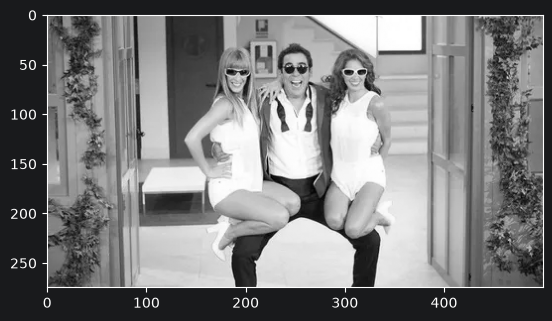

In [57]:
import cv2
mi_imagen=cv2.imread('miImagen.png',cv2.IMREAD_GRAYSCALE)
plt.imshow(mi_imagen, cmap='gray')

13. Veamos ahora las capas en tu modelo. Experimenta con diferentes valores para la capa densa con 512 neuronas. ¿Qué resultados diferentes obtienes para la pérdida, el tiempo de entrenamiento, etc.? ¿Por qué crees que es así?
Incrementa la capa oculta a 1024 neuronas -- ¿Cuál es el impacto?
    a) El entrenamiento lleva más tiempo, pero es más preciso
    b) El entrenamiento lleva más tiempo, pero no afecta la precisión
    c) El entrenamiento lleva el mismo tiempo, pero es más preciso

In [58]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [59]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [60]:
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8293 - loss: 0.4787
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8686 - loss: 0.3613
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8814 - loss: 0.3220
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8899 - loss: 0.2978
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8968 - loss: 0.2793


In [61]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [62]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [63]:
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8326 - loss: 0.4668
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8694 - loss: 0.3561
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8829 - loss: 0.3195
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8909 - loss: 0.2957
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8958 - loss: 0.2780


14. ¿Qué pasaría si eliminas la capa Flatten()? ¿Por qué crees que es así?

In [64]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [65]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5


ValueError: Argument `output` must have rank (ndim) `target.ndim - 1`. Received: target.shape=(32,), output.shape=(32, 28, 10)

In [71]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [72]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 731us/step - accuracy: 0.2795 - loss: 1.7826
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 704us/step - accuracy: 0.3771 - loss: 1.4854
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 706us/step - accuracy: 0.3985 - loss: 1.3796
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 719us/step - accuracy: 0.4215 - loss: 1.3173
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 733us/step - accuracy: 0.5137 - loss: 1.2368
